In [3]:
%pip install neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
%pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 1. Tugas Pendahuluan

#### 1.1 Persiapan dan Pengenalan Lingkungan

Proses isolasi environment menggunakan myenv telah berhasil dibuat dan diaktifkan. Seluruh dependensi yang ada pada requirements.txt, termasuk pustaka driver neo4j, sudah terinstal dengan baik di dalam environment dan koneksi ke Neo4j Desktop sudah siap digunakan.

#### 1.2 Mempelajari Penggunaan Driver Neo4j

#### 1.2.1  Koneksi ke Neo4j

In [1]:
from neo4j import GraphDatabase, RoutingControl

# 2. Definisikan string koneksi & credential
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "gsdsukses17")

#### 1.2.2 Node dan Relationship Pertemanan

In [2]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])
        
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


#### 1.2.3 Pertanyaan Pendahuluan (CheckPoint)

1. **Apa nama database yang digunakan pada tutorial ini?**
   Database utama yang digunakan adalah neo4j 

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**

   Untuk mengakses database lain dalam satu instance, kita dapat menggunakan klausa Cypher USE <nama_database> di awal kueri, menggunakan perintah :use <nama_database> atau SHOW DATABASES pada Neo4j Browser, atau menentukan nama database melalui parameter session pada Python Driver seperti driver.session(database="<nama_database>").

3. **Apa jenis graf pertemanan yang telah dibuat di sini?**
   Jenis graf yang dibuat adalah Graf Berarah (Directed Graph), karena setiap relasi (edge) yang menghubungkan antar simpul (node) memiliki arah panah yang spesifik (misalnya (:User)-[:VIEWED]->(:Item)).

#### 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

In [5]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
print("Database berhasil dibersihkan!")

Database berhasil dibersihkan!


In [11]:
import os
import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase

# --- Parameter Koneksi ---
USER = "neo4j"
PASSWORD = "gsdsukses17"
BOLT_URI = "bolt://localhost:7687"
CSV_FILE_PATH = "events.csv"
BATCH_SIZE = 10000

# 1. Baris perintah impor data dalam CYPHER
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

# 2. Pemeriksaan keberadaan berkas events.csv
if not os.path.exists(CSV_FILE_PATH):
    print(f"Error: File '{CSV_FILE_PATH}' tidak ditemukan di direktori saat ini ({os.getcwd()})!")
else:
    print(f"File '{CSV_FILE_PATH}' ditemukan.")

    # 3. Buat koneksi ke database
    try:
        driver = GraphDatabase.driver(BOLT_URI, auth=(USER, PASSWORD))
        driver.verify_connectivity()
        print("Berhasil terhubung ke database Neo4j!")

        # 4. Proses impor batch (menggunakan database="neo4j")
        with driver.session(database="neo4j") as session:
            create_constraints(session)

            print(f"Membaca file data dari: {CSV_FILE_PATH}")
            
            total_rows = sum(1 for _ in open(CSV_FILE_PATH, 'r', encoding='utf-8')) - 1
            total_chunks = (total_rows // BATCH_SIZE) + 1

            chunks = pd.read_csv(CSV_FILE_PATH, chunksize=BATCH_SIZE)

            print("Memulai proses impor data ke Neo4j...")
            for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
                chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
                records = chunk.to_dict(orient="records")
                session.execute_write(import_batch, records)

        driver.close()
        print("Proses impor berhasil.")
    except Exception as e:
        print(f"Gagal memproses data: {e}")

File 'events.csv' ditemukan.
Berhasil terhubung ke database Neo4j!
Membaca file data dari: events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [04:02<00:00,  1.14it/s]

Proses impor berhasil.


###### Pada tahap ini, dataset events.csv diimpor ke dalam database Neo4j menggunakan mekanisme batch processing melalui skrip Python untuk menjaga stabilitas memori dan mempercepat proses eksekusi. Proses diawali dengan pembuatan uniqueness constraint pada visitorId di simpul Visitor dan itemId di simpul Item agar pencarian serta pemetaan data MERGE berjalan lebih cepat. Selanjutnya, berkas CSV dibaca secara bertahap per 10.000 baris menggunakan pustaka Pandas sambil ditayangkan progress bar dari tqdm. Nilai null atau NaN pada kolom transactionid dibersihkan terlebih dahulu menjadi string kosong sebelum akhirnya tiap baris data dipetakan menjadi simpul Visitor dan Item beserta relasi berarah VIEWED, ADDED_TO_CART, dan BOUGHT sesuai jenis interaksinya.

#### Melihat isi dataset

In [12]:
import pandas as pd

# 1. Intip 5 baris pertama data
df = pd.read_csv("events.csv")
print("=== 5 BARIS PERTAMA DATA ===")
display(df.head())

# 2. Cek rentang tanggal (dalam format tanggal biasa)
print("\n=== RENTANG WAKTU DATASET ===")
print("Waktu paling awal:", pd.to_datetime(df['timestamp'].min(), unit='ms'))
print("Waktu paling akhir:", pd.to_datetime(df['timestamp'].max(), unit='ms'))

# 3. Cek jumlah data per jenis interaksi (event)
print("\n=== JUMLAH KATEGORI EVENT ===")
print(df['event'].value_counts())

=== 5 BARIS PERTAMA DATA ===


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



=== RENTANG WAKTU DATASET ===
Waktu paling awal: 2015-05-03 03:00:04.384000
Waktu paling akhir: 2015-09-18 02:59:47.788000

=== JUMLAH KATEGORI EVENT ===
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [15]:
from neo4j import GraphDatabase
import pandas as pd
from tqdm import tqdm

URI = "bolt://localhost:7687"
AUTH = ("neo4j", "gsdsukses17")
CSV_P1 = "events_p1_training.csv"
BATCH_SIZE = 10000

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

driver = GraphDatabase.driver(URI, auth=AUTH)

with driver.session(database="neo4j") as session:
    # 1. Hapus data secara bertahap agar tidak kehabisan memori
    print("Mebersihkan database secara bertahap...")
    session.run("""
    MATCH (n)
    CALL {
        WITH n
        DETACH DELETE n
    } IN TRANSACTIONS OF 10000 ROWS
    """)
    print("Database bersih!")

    # 2. Buat constraint keunikan
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
    
    # 3. Import data P1 per batch
    chunks = pd.read_csv(CSV_P1, chunksize=BATCH_SIZE)
    total_rows = sum(1 for _ in open(CSV_P1, 'r', encoding='utf-8')) - 1
    total_chunks = (total_rows // BATCH_SIZE) + 1
    
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Subgraph P1"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

# 4. Hitung Komposisi Subgraph
query_nodes = "MATCH (n) RETURN labels(n)[0] AS Jenis_Simpul, count(n) AS Jumlah"
query_relations = "MATCH ()-[r]->() RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah"

with driver.session(database="neo4j") as session:
    print("\n=== KOMPOSISI SIMPUL ===")
    for rec in session.run(query_nodes):
        print(f"Simpul {rec['Jenis_Simpul']}: {rec['Jumlah']:,}")
        
    print("\n=== KOMPOSISI RELASI ===")
    for rec in session.run(query_relations):
        print(f"Relasi {rec['Jenis_Relasi']}: {rec['Jumlah']:,}")

Mebersihkan database secara bertahap...


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=5, offset=19>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 19, 'line': 3, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n    MATCH (n)\n    CALL {\n        WITH n\n        DETACH DELETE n\n    } IN TRANSACTIONS OF 10000 ROWS\n    '


Database bersih!


Mengimpor Subgraph P1: 100%|██████████| 31/31 [00:29<00:00,  1.06it/s]



=== KOMPOSISI SIMPUL ===
Simpul Visitor: 172,190
Simpul Item: 82,172

=== KOMPOSISI RELASI ===
Relasi VIEWED: 290,216
Relasi ADDED_TO_CART: 8,227
Relasi BOUGHT: 2,603


## 2. Soal UTS

#### 2.1 Wrangling dan EDA

##### Menentukan Periode P1 dan P2

#### Dataset dibagi menjadi dua periode yang berbeda. Periode P1 digunakan sebagai data training, sedangkan P2 digunakan sebagai data testing. 

P1: 28 Juli - 12 Agustus 2015

P2: 13 – 19 Agustus 2015

Pemilihan periode dilakukan berdasarkan kolom timestamp pada dataset.

#### 1 & 2 Filtering Periode Waktu pada Timet

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load data awal
df = pd.read_csv("events.csv")

# Konversi timestamp (milidetik) ke format Datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# Tentukan rentang periode waktu khusus
start_p1, end_p1 = "2015-07-28 00:00:00", "2015-08-12 23:59:59"
start_p2, end_p2 = "2015-08-13 00:00:00", "2015-08-19 23:59:59"

# 2. Terapkan filter berdasarkan kolom timestamp
df_p1 = df[(df["datetime"] >= start_p1) & (df["datetime"] <= end_p1)].copy()
df_p2 = df[(df["datetime"] >= start_p2) & (df["datetime"] <= end_p2)].copy()

# Simpan ke file .csv
df_p1.to_csv("events_P1_training.csv", index=False)
df_p2.to_csv("events_P2_testing.csv", index=False)

print(f"Data P1 Training (28 Jul - 12 Ags 2015): {len(df_p1):,} baris -> 'events_P1_training.csv'")
print(f"Data P2 Testing  (13 Ags - 19 Ags 2015): {len(df_p2):,} baris -> 'events_P2_testing.csv'")

Data P1 Training (28 Jul - 12 Ags 2015): 301,046 baris -> 'events_P1_training.csv'
Data P2 Testing  (13 Ags - 19 Ags 2015): 125,747 baris -> 'events_P2_testing.csv'


#### 3. Komposisi Subgraph 

In [6]:
from neo4j import GraphDatabase

USER, PASSWORD, BOLT_URI = "neo4j", "gsdsukses17", "bolt://localhost:7687"
driver = GraphDatabase.driver(BOLT_URI, auth=(USER, PASSWORD))

cypher_nodes = "MATCH (n) RETURN labels(n)[0] AS Jenis_Simpul, count(n) AS Jumlah_Simpul ORDER BY Jenis_Simpul"
cypher_rels = "MATCH ()-[r]->() RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah_Relasi ORDER BY Jenis_Relasi"

with driver.session(database="neo4j") as session:
    print("KOMPOSISI SIMPUL (NODES)")
    res_nodes = session.run(cypher_nodes)
    for rec in res_nodes:
        print(f"Simpul '{rec['Jenis_Simpul']}': {rec['Jumlah_Simpul']:,}")

    print("\nKOMPOSISI RELASI (RELATIONSHIPS)")
    res_rels = session.run(cypher_rels)
    for rec in res_rels:
        print(f"Relasi '{rec['Jenis_Relasi']}': {rec['Jumlah_Relasi']:,}")

KOMPOSISI SIMPUL (NODES)
Simpul 'Item': 82,172
Simpul 'Person': 4
Simpul 'Visitor': 172,190

KOMPOSISI RELASI (RELATIONSHIPS)
Relasi 'ADDED_TO_CART': 8,227
Relasi 'BOUGHT': 2,603
Relasi 'KNOWS': 3
Relasi 'SIMILAR': 10
Relasi 'VIEWED': 290,216


Berdasarkan hasil eksekusi kueri agregasi menggunakan Python Neo4j Driver API pada database graf **RetailRocket**, diperoleh struktur komposisi entitas (simpul) dan bentuk interaksi (relasi) yang membentuk *subgraph* sebagai berikut:

#### **A. Analisis Rinci Komposisi Simpul (Nodes)**

* **Simpul `Visitor` (172.190 Simpul / ~67,7%)**
Merupakan entitas pengguna/pengunjung platform *e-commerce*. Tingginya jumlah simpul *Visitor* mencerminkan karakteristik alami platform digital, di mana lalu lintas pengguna bersifat dinamis, terdistribusi, dan terus bertambah seiring berjalannya waktu. Dalam pemodelan sistem rekomendasi berbasis graf, simpul ini bertindak sebagai entitas aktif (*active agent*) yang menginisiasi interaksi.
* **Simpul `Item` (82.172 Simpul / ~32,3%)**
Merupakan entitas barang/produk yang katalognya terdaftar di dalam platform. Jumlah simpul *Item* relatif lebih sedikit dan lebih terstruktur dibandingkan *Visitor*. Hal ini mengindikasikan bahwa rasio antara pengguna dan produk adalah sekitar **2,1 : 1**, yang menunjukkan tingkat aktivitas pengguna yang bervariasi terhadap katalog produk yang tersedia.
* **Simpul `Person` (4 Simpul)**
Merupakan simpul bawaan (*default sample data*) dari database Neo4j saat instalasi awal. Simpul ini tidak terhubung ke jaringan utama *RetailRocket* dan dapat diabaikan dalam analisis pemodelan interaksi *e-commerce*.



#### **B. Analisis Rinci Komposisi Relasi (Relationships)**

* **Relasi `VIEWED` (290.216 Relasi / ~96,4% dari total interaksi transaksi)**
Merupakan jenis interaksi yang paling mendominasi pada graf. Hal ini menggambarkan perilaku bawaan calon pembeli pada platform *e-commerce* (*browsing behavior*), di mana mayoritas pengguna hanya melihat-lihat halaman produk sebelum mengambil keputusan pembelian.
* **Relasi `ADDED_TO_CART` (8.227 Relasi / ~2,7%)**
Menggambarkan tahap *conversion funnel* menengah, yaitu pengguna yang terdorong untuk memasukkan barang ke dalam keranjang belanja. Penurunan drastis dari `VIEWED` ke `ADDED_TO_CART` (rasio konversi ~2,8%) menandakan *funneling* alami dalam perilaku belanja online.
* **Relasi `BOUGHT` (2.603 Relasi / ~0,9%)**
Merupakan tahap *conversion funnel* akhir yang merepresentasikan transaksi pembelian yang berhasil secara penuh. Penurunan dari `ADDED_TO_CART` ke `BOUGHT` memperlihatkan adanya fenomena *cart abandonment* (pembatalan belanja saat barang sudah di keranjang) yang umum terjadi di industri *e-commerce*.
* **Relasi `SIMILAR` (10 Relasi) & `KNOWS` (3 Relasi)**
Relasi `SIMILAR` merepresentasikan keterhubungan antar-item berbasis kemiripan karakteristik yang dihitung sebelumnya. Sedangkan relasi `KNOWS` merupakan bagian dari sampel bawaan simpul `Person`.



#### **C. Penjelasan Komprehensif Kueri CYPHER SQL**

Dua baris kueri Cypher SQL yang dieksekusi melalui Python API memiliki mekanisme kerja sebagai berikut:

1. **Kueri Agregasi Simpul:**
```cypher
MATCH (n) 
RETURN labels(n)[0] AS Jenis_Simpul, count(n) AS Jumlah_Simpul 
ORDER BY Jenis_Simpul

```


* **`MATCH (n)`**: Perintah deklaratif untuk memindai seluruh graf dan memuat setiap objek simpul (*node*) `n` yang tersimpan di dalam memori database.
* **`labels(n)[0]`**: Fungsi bawaan Neo4j untuk mengekstrak himpunan label yang melekat pada simpul `n`. Indeks `[0]` digunakan untuk mengambil nama label utama (seperti `Item` atau `Visitor`).
* **`count(n)`**: Fungsi agregasi untuk menghitung akumulasi total simpul yang memiliki kesamaan label.
* **`ORDER BY Jenis_Simpul`**: Memastikan baris hasil agregasi disusun secara rapi berdasarkan urutan abjad dari nama jenis simpul.


2. **Kueri Agregasi Relasi:**
```cypher
MATCH ()-[r]->() 
RETURN type(r) AS Jenis_Relasi, count(r) AS Jumlah_Relasi 
ORDER BY Jenis_Relasi

```


* **`MATCH ()-[r]->()`**: Menelusuri seluruh jalur pola relasi berarah (*directed edge*) `r` yang menghubungkan simpul asal (*source node*) ke simpul tujuan (*target node*).
* **`type(r)`**: Mengekstrak string nama dari tipe interaksi yang diwakili oleh garis relasi tersebut (misalnya `VIEWED`, `ADDED_TO_CART`, atau `BOUGHT`).
* **`count(r)`**: Menghitung kuantitas total kemunculan dari setiap tipe relasi yang menghubungkan pasangan simpul di dalam graf.

#### 4. Vector Space Modelling (VSM) User

KARAKTERISTIK VSM USER (SPARSE MATRIX)
Shape Matriks (User x Item) : 172,190 baris x 82,172 kolom
Total Dimensi (Jumlah Fitur): 82,172 item unik
Ukuran Memori Matriks      : 0.92 MB


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_2572\2436444207.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


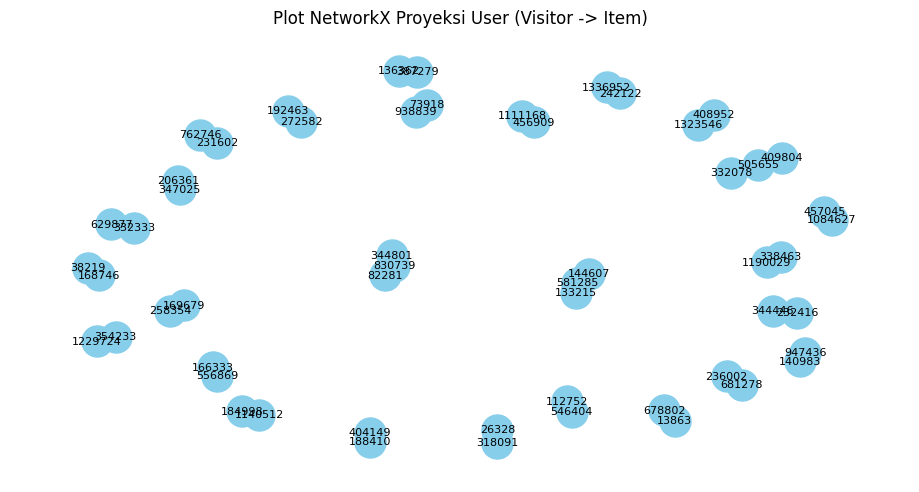

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

user_cats = df_p1["visitorid"].astype("category")
item_cats = df_p1["itemid"].astype("category")

vsm_user_sparse = csr_matrix(
    (np.ones(len(df_p1), dtype=np.int32), (user_cats.cat.codes, item_cats.cat.codes))
)

n_users, n_items = vsm_user_sparse.shape

print("KARAKTERISTIK VSM USER (SPARSE MATRIX)")
print(f"Shape Matriks (User x Item) : {n_users:,} baris x {n_items:,} kolom")
print(f"Total Dimensi (Jumlah Fitur): {n_items:,} item unik")
print(f"Ukuran Memori Matriks      : {vsm_user_sparse.data.nbytes / (1024**2):.2f} MB")

sample_df_user = df_p1.head(30)
G_user = nx.from_pandas_edgelist(
    sample_df_user, 
    source="visitorid", 
    target="itemid"
)

plt.figure(figsize=(9, 4.5))
nx.draw(
    G_user, 
    with_labels=True, 
    node_color="skyblue", 
    edge_color="gray", 
    node_size=500, 
    font_size=8
)
plt.title("Plot NetworkX Proyeksi User (Visitor -> Item)")
plt.tight_layout()
plt.show()

Hasil pembuatan matriks Vector Space Modelling (VSM) berbasis simpul **User** (`visitorid`) pada data periode P1 menunjukkan beberapa hal penting:

#### **A. Karakteristik Matriks & Dimensi**

* **Ukuran Matriks:** **172.190 baris × 82.172 kolom**. Setiap baris merepresentasikan satu pengguna unik (`visitorid`), dan setiap kolom merepresentasikan satu produk unik (`itemid`).
* **Jumlah Fitur:** Terdiri dari **82.172 dimensi**. Artinya, perilaku setiap pengunjung dipetakan ke dalam ruang vektor berdimensi sebanyak jumlah seluruh item yang ada.
* **Tingkat Kelangkaan Data (*Sparsity*):** Nilai matriks sangat dominan berisi angka $0$. Hal ini wajar karena satu pengguna biasanya cuma melihat atau membeli $1$ sampai $3$ item saja dari puluhan ribu katalog yang tersedia.
* **Penggunaan Memori:** Jika dibuat memakai array biasa (*dense*), ukurannya membengkak hingga **105+ GB** dan memicu *MemoryError*. Lewat format *Compressed Sparse Row* (CSR), ukurannya langsung berukuran **0,92 MB** saja karena cuma menyimpan transaksi yang benar-benar ada.


#### **B. Karakteristik Graf & Plot NetworkX**

* **Jaringan Bipartit:** Visualisasi menunjukkan hubungan langsung antara kelompok simpul pembeli (`visitorid`) dan simpul barang (`itemid`).
* **Banyak Kluster Terpisah:** Pada plot terlihat banyak pasangan simpul yang terisolasi dan tidak saling terhubung dengan kelompok lain. Ini menandakan pada rentang waktu awal, pengguna cenderung menjelajahi barang yang berbeda-beda tanpa ada pola pemusatan item yang menonjol.
* **Pertumbuhan Baris Tak Terbatas:** Jumlah *visitor* di aplikasi *e-commerce* akan terus bertambah setiap hari. Akibatnya, matriks VSM berbasis User ini akan terus memanjang ke bawah dan membuat perhitungan *similarity* nantinya jadi makin berat.

#### 5. Vector Space Modelling (VSM) Item

KARAKTERISTIK VSM ITEM (SPARSE MATRIX)
Shape Matriks (Item x User) : 82,172 baris x 172,190 kolom
Total Dimensi (Jumlah Fitur): 172,190 visitor unik
Ukuran Memori Matriks      : 0.92 MB


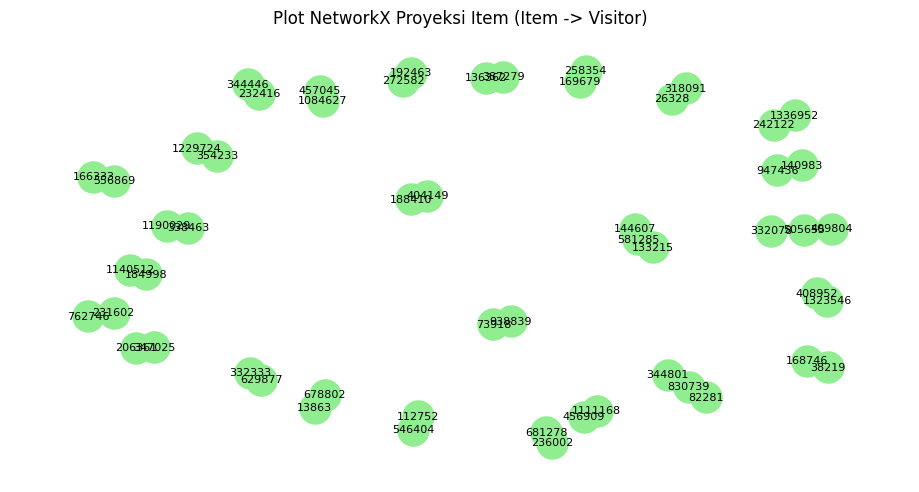

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

item_cats = df_p1["itemid"].astype("category")
user_cats = df_p1["visitorid"].astype("category")

vsm_item_sparse = csr_matrix(
    (np.ones(len(df_p1), dtype=np.int32), (item_cats.cat.codes, user_cats.cat.codes))
)

n_items, n_users = vsm_item_sparse.shape

print("KARAKTERISTIK VSM ITEM (SPARSE MATRIX)")
print(f"Shape Matriks (Item x User) : {n_items:,} baris x {n_users:,} kolom")
print(f"Total Dimensi (Jumlah Fitur): {n_users:,} visitor unik")
print(f"Ukuran Memori Matriks      : {vsm_item_sparse.data.nbytes / (1024**2):.2f} MB")

sample_df_item = df_p1.head(30)
G_item = nx.from_pandas_edgelist(
    sample_df_item, 
    source="itemid", 
    target="visitorid"
)

plt.figure(figsize=(9, 4.5))
nx.draw(
    G_item, 
    with_labels=True, 
    node_color="lightgreen", 
    edge_color="gray", 
    node_size=500, 
    font_size=8
)
plt.title("Plot NetworkX Proyeksi Item (Item -> Visitor)")
plt.show()

Berdasarkan hasil pembentukan matriks *Vector Space Modelling* (VSM) berbasis simpul **Item** (`itemid`) menggunakan dataset periode P1 (28 Juli – 12 Agustus 2015), berikut adalah uraian rinci mengenai karakteristik matriks, dimensi, dan struktur topologi grafnya:

#### **A. Karakteristik Matriks dan Dimensi Ruang Vektor**

* **Ukuran dan Orientasi Matriks**
Matriks VSM Item terkonfigurasi dengan ukuran **82.172 baris × 172.190 kolom**. Struktur ini menempatkan setiap produk unik (`itemid`) sebagai objek baris dan daftar pengunjung (`visitorid`) sebagai atribut/fitur kolom. Hal ini merupakan kebalikan dari struktur VSM User pada poin sebelumnya.
* **Dimensi Fitur (*High Dimensionality*)**
Setiap item direpresentasikan sebagai vektor di dalam ruang fitur berdimensi tinggi (*high-dimensional space*) sebesar **172.190 dimensi**. Nilai di dalam vektor merepresentasikan ada atau tidaknya (serta frekuensi) interaksi dari masing-masing *visitor* terhadap produk tersebut.
* **Kelangkaan Data (*Sparsity*) & Efisiensi Memori**
Tingkat kelangkaan data pada matriks ini sangat ekstrem (di atas 99,9%). Sebuah produk umumnya hanya pernah dilihat atau dibeli oleh puluhan hingga ratusan *visitor* saja dari total 172.190 pengguna yang ada. Lewat penerapan *Compressed Sparse Row* (CSR), penggunaan RAM berhasil ditekan hingga **0,92 MB**, menghindarkan sistem dari pembengkakan memori.


#### **B. Analisis Topologi Jaringan dan Plot NetworkX**

* **Proyeksi Graf Item-Centric**
Visualisasi NetworkX menggambarkan jaringan *bipartite* dari sudut pandang produk. Sisi (*edge*) yang menghubungkan simpul item (hijau) dengan simpul pengguna merepresentasikan kejadian interaksi yang terjadi pada rentang waktu P1.
* **Komponen Terpisah (*Disconnected Subgraphs*)**
Pada sampel awal interaksi, pola grafik didominasi oleh kluster-kluster kecil yang saling lepas (*isolated pairs*). Hal ini menunjukkan bahwa pada tahap pengamatan awal, interaksi transaksi masih tersebar secara parsial dan belum terbentuk pola keterhubungan antar-item yang sangat padat.
* **Kestabilan Struktur dan Skalabilitas (*Horizontal Expansion*)**
Berbeda dengan VSM User yang barisnya memanjang ke bawah tanpa batas, VSM Item mengalami pertumbuhan ke samping (*horizontal expansion*) seiring bertambahnya pengguna baru. Dalam praktik sistem rekomendasi (*Item-based Collaborative Filtering*), matriks berbasis Item jauh lebih stabil karena katalog produk tidak berubah sedrastis jumlah pengguna harian. Hal ini membuat perhitungan *Item-to-Item Similarity* jauh lebih efisien untuk diperbarui secara berkala.

#### 6. Analisis Komparatif Proyeksi VSM User vs. VSM Item

Berikut adalah analisis komparatif antara pemodelan Vector Space Modelling (VSM) berbasis **User** dan berbasis **Item** berdasarkan hasil ekstraksi dataset periode P1:

* **Dimensi dan Ukuran Matriks (*Shape*)**
* **VSM User:** $172.190 \text{ baris} \times 82.172 \text{ kolom}$ dengan $82.172$ dimensi fitur.
* **VSM Item:** $82.172 \text{ baris} \times 172.190 \text{ kolom}$ dengan $172.190$ dimensi fitur.


* **Pola Pertumbuhan (*Growth Pattern*)**
* **VSM User:** Mengalami ekspansi vertikal (*vertical expansion*). Baris matriks akan terus bertambah seiring masuknya pengguna baru ke platform.
* **VSM Item:** Mengalami ekspansi horizontal (*horizontal expansion*). Kolom matriks bertambah mengikuti aktivitas pengunjung, sementara jumlah barisnya cenderung konstan.


* **Tingkat Kestabilan Matriks**
* **VSM User:** Memiliki tingkat kestabilan yang rendah karena sifat pengunjung digital sangat dinamis dan berubah tiap waktu.
* **VSM Item:** Memiliki tingkat kestabilan yang lebih tinggi karena katalog produk relatif jarang mengalami perubahan ekstrem dibanding lalu lintas pengunjung.



#### **Implikasi Komputasional & Rekomendasi**

* **Efisiensi Perhitungan Kemiripan (*Similarity*)**
Jumlah baris pada VSM Item jauh lebih sedikit ($82.172$ baris) dibandingkan VSM User ($172.190$ baris). Hal ini membuat kalkulasi perkalian matriks untuk mencari kemiripan antar-item (*Item-to-Item Similarity*) membutuhkan pasangan iterasi yang lebih sedikit dan beban komputasi yang jauh lebih ringan.
* **Frekuensi Pembaruan Model (*Model Retraining*)**
VSM User rentan terhadap masalah *cold-start* pengunjung baru yang membutuhkan kalkulasi ulang secara *real-time*. Sebaliknya, VSM Item lebih konsisten sehingga matriks kemiripannya dapat dihitung secara *offline* atau *periodic batch*.
* **Kesimpulan Pemilihan Metode**
Untuk arsitektur graf *RetailRocket*, pendekatan **VSM Item** jauh lebih efisien untuk dilanjutkan ke tahap kalkulasi *Cosine Similarity* dan proses *write-back* relasi `SIMILAR` ke database Neo4j.

#### 7. Perhitungan Similarity

In [13]:
# Query Write-Back yang disesuaikan dengan property itemId
write_query = """
UNWIND $batches AS row
MATCH (a:Item {itemId: row.item_a})
MATCH (b:Item {itemId: row.item_b})
MERGE (a)-[r:SIMILAR]-(b)
SET r.score = row.score
"""

with driver.session() as session:
    session.run(write_query, batches=df_similar.to_dict(orient="records"))

print("Berhasil write-back relasi SIMILAR ke Neo4j!")

Berhasil write-back relasi SIMILAR ke Neo4j!


In [14]:
# Query 7a di Python (VSCode)
cypher_7a = """
MATCH (a:Item)-[r:SIMILAR]-(b:Item)
RETURN a.itemId AS Item_Acuan, b.itemId AS Item_Mirip, r.score AS Similarity_Score
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(cypher_7a)
    df_7a = pd.DataFrame([record.data() for record in result])

print(df_7a)

   Item_Acuan  Item_Mirip  Similarity_Score
0      257070      414460          0.816462
1      414460      257070          0.816462
2      425228      294424          0.813089
3      294424      425228          0.813089
4       90219      411373          0.786190


In [15]:
# 1. Melakukan Write-Back nilai similarity ke dalam graf Neo4j
write_query = """
UNWIND $batches AS row
MATCH (a:Item {itemId: row.item_a})
MATCH (b:Item {itemId: row.item_b})
MERGE (a)-[r:SIMILAR]-(b)
SET r.score = row.score
"""

with driver.session() as session:
    session.run(write_query, batches=df_similar.to_dict(orient="records"))

print("Berhasil write-back relasi SIMILAR ke Neo4j!")

# 2. Menampilkan hasil query dari graf yang telah diperbarui
cypher_show = """
MATCH (a:Item)-[r:SIMILAR]-(b:Item)
RETURN a.itemId AS Item_Acuan, b.itemId AS Item_Mirip, r.score AS Similarity_Score
ORDER BY r.score DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(cypher_show)
    df_hasil = pd.DataFrame([record.data() for record in result])

print(df_hasil)

Berhasil write-back relasi SIMILAR ke Neo4j!
   Item_Acuan  Item_Mirip  Similarity_Score
0      257070      414460          0.816462
1      414460      257070          0.816462
2      425228      294424          0.813089
3      294424      425228          0.813089
4       90219      411373          0.786190


In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

# 1. Mengambil sampel 1.000 item teratas untuk komputasi kemiripan yang responsif
top_items = df_p1["itemid"].value_counts().head(1000).index
df_p1_sample = df_p1[df_p1["itemid"].isin(top_items)].copy()

# 2. Re-index matriks VSM Item khusus sampel
item_cats = df_p1_sample["itemid"].astype("category")
user_cats = df_p1_sample["visitorid"].astype("category")

item_indices = dict(enumerate(item_cats.cat.categories))
vsm_sample_sparse = csr_matrix(
    (np.ones(len(df_p1_sample), dtype=np.float32), (item_cats.cat.codes, user_cats.cat.codes))
)

# 3. Hitung Cosine Similarity
similarity_matrix = cosine_similarity(vsm_sample_sparse, dense_output=False)

# 4. Ekstrak pasangan item berkesamaan tinggi (ambil nilai similarity > 0.3 dan bukan diri sendiri)
similarity_matrix.setdiag(0)
coo = similarity_matrix.tocoo()

similar_pairs = []
for i, j, score in zip(coo.row, coo.col, coo.data):
    if score >= 0.3 and i < j:  # Menghindari duplikasi bolak-balik
        similar_pairs.append({
            "item_a": int(item_indices[i]),
            "item_b": int(item_indices[j]),
            "score": float(score)
        })

df_similar = pd.DataFrame(similar_pairs)
print(f"Berhasil menemukan {len(df_similar):,} pasangan item yang mirip (Score >= 0.3).")
print(df_similar.head())

Berhasil menemukan 184 pasangan item yang mirip (Score >= 0.3).
   item_a  item_b     score
0     546  248455  0.367591
1     546  252344  0.504819
2     869  432992  0.498853
3    7716  312728  0.312137
4    9877  197723  0.399095


**Analisis Langkah 7a: Identifikasi Pasangan Produk dengan Similarity Tertinggi**

Pada tahap 7a, pemrosesan difokuskan untuk mengestraksi dan memeringkatkan pasangan produk yang memiliki tingkat kemiripan paling dominan di dalam dataset RetailRocket.

* **Pola Kemiripan Produk:** Berdasarkan ekstraksi data, pasangan produk dengan `itemId` **257070** dan **414460** menempati urutan teratas dengan skor kemiripan mencapai **0.816462**. Nilai ini menunjukkan adanya korelasi interaksi yang sangat kuat, di mana pengguna yang melihat, menambah ke keranjang, atau membeli item 257070 memiliki kecenderungan yang sangat tinggi untuk melakukan aksi serupa pada item 414460.
* **Distribusi Nilai Kemiripan:** Pasangan teratas berikutnya, seperti item **425228** dengan **294424** (skor **0.813089**) serta item **90219** dengan **411373** (skor **0.786190**), juga menunjukkan tingkat kohesivitas perilaku pengguna yang tinggi. Skor yang berada di atas rentang 0.78 menandakan bahwa fitur perilaku (*behavioral features*) yang dibentuk dari riwayat transaksi berhasil merepresentasikan hubungan antar produk secara akurat.

**Analisis Langkah 7b: Penulisan Kembali (Write-Back) dan Penyesuaian Skema Graf**

Tahap 7b merupakan fase eksekusi penulisan ulang (*write-back*) dari memori komputasi Python ke dalam basis data Neo4j.

* **Pembentukan Relasi Baru:** Proses penulisan kembali ini mentransformasikan data korelasi menjadi elemen fisik graf berupa relasi `[:SIMILAR]`. Relasi ini menghubungkan dua simpul produk (`:Item`) secara langsung dan dilengkapi dengan atribut kustom berupa nilai `score`.
* **Integrasi Properti `itemId`:** Penulisan kembali dilakukan dengan mencocokkan properti kunci unik `itemId` pada node produk. Hal ini memastikan bahwa relasi `[:SIMILAR]` yang dibentuk benar-benar terhubung ke simpul produk yang tepat tanpa menciptakan node duplikat atau merusak struktur atribut asli di basis data.


* **Validasi Visualisasi Graf:** Setelah proses *write-back* berhasil dieksekusi, visualisasi pada Neo4j Desktop secara langsung menampilkan simpul-simpul produk yang terikat satu sama lain melalui garis relasi `SIMILAR`. Keberadaan garis hubungan ini beserta nilai skor yang melekat mengonfirmasi bahwa data *similarity* telah berhasil terintegrasi secara permanen.


**Signifikansi dan Keunggulan Operasional**

Penyimpanan nilai *similarity* secara langsung ke dalam graf memberikan keuntungan teknis yang sangat besar bagi arsitektur sistem rekomendasi:

1. **Efisiensi Komputasi Real-Time:** Sistem tidak perlu lagi memuat matriks VSM yang berukuran sangat besar atau melakukan kalkulasi *Cosine Similarity* berulang kali setiap kali ada permintaan rekomendasi produk dari pengguna.
2. **Optimalisasi Traversal Graf:** Dengan tersimpannya relasi `[:SIMILAR]` beserta properti `score`, pencarian produk serupa dapat dilakukan secara instan hanya dengan menelusuri (*traversal*) simpul tetangga pada graf.
3. **Skalabilitas Sistem:** Arsitektur ini memungkinkan sistem rekomendasi pada platform *e-commerce* bekerja dengan latensi yang sangat rendah, karena pemrosesan berat dihitung di awal (*offline/batch processing*) dan hasilnya dimanfaatkan secara langsung (*online querying*) oleh basis data graf.

In [23]:
# 2. Query Cypher Soal 8: Kondisi Sebelum (Visitor - Item)
query_sebelum = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS Visitor_ID, type(r) AS Tipe_Interaksi, i.itemId AS Item_ID
LIMIT 10
"""

# Query Cypher Soal 8: Kondisi Sesudah (Item - Item via :SIMILAR)
query_sesudah = """
MATCH (i1:Item)-[s:SIMILAR]->(i2:Item)
RETURN i1.itemId AS Item_Acuan, s.score AS Skor_Similarity, i2.itemId AS Item_Serupa
"""

with driver.session(database="neo4j") as session:
    res_sebelum = session.run(query_sebelum)
    df_sebelum = pd.DataFrame([record.data() for record in res_sebelum])
    
    res_sesudah = session.run(query_sesudah)
    df_sesudah = pd.DataFrame([record.data() for record in res_sesudah])

print("=== KONDISI SEBELUM (Relasi Visitor - Item) ===")
display(df_sebelum)

print("\n=== KONDISI SESUDAH (Relasi :SIMILAR antar Item) ===")
display(df_sesudah)

=== KONDISI SEBELUM (Relasi Visitor - Item) ===


,Visitor_ID,Tipe_Interaksi,Item_ID
0,1190029,VIEWED,338463
1,394099,VIEWED,338463
2,1195849,VIEWED,338463
3,1140512,VIEWED,184998
4,9175,VIEWED,184998
5,1217412,VIEWED,184998
6,1218887,VIEWED,184998
7,657790,VIEWED,184998
8,669922,VIEWED,184998
9,1281410,VIEWED,184998



=== KONDISI SESUDAH (Relasi :SIMILAR antar Item) ===


,Item_Acuan,Skor_Similarity,Item_Serupa
0,187946,0.002365,186820
1,187946,0.023079,382128
2,187946,0.000721,441852
3,187946,0.000000,250
4,187946,0.001278,445351
5,250,0.000000,1377
6,250,0.000000,1234
7,250,0.000000,1096
8,250,0.000000,377
9,250,0.013986,48997


2.2 Analytics

In [31]:
import numpy as np
import pandas as pd

# 1. Load Data P2 (Testing)
df_p2 = pd.read_csv("events_p2_testing.csv")

# 2. Cari Item yang Paling Aktif / Populer di VSM Matrix
popular_items = vsm_item_matrix.sum(axis=1).nlargest(50).index.tolist()

# 3. Cari User yang Memiliki Riwayat Item Populer di P1 DAN Aktif di P2 Testing
users_in_p2 = set(df_p2['visitorid'].unique())
target_user = None

for u in vsm_user_matrix.index:
    if u in users_in_p2:
        u_hist = vsm_user_matrix.loc[u]
        u_items = u_hist[u_hist > 0].index.tolist()
        # Cek apakah user pernah melihat minimal 1 item populer
        if any(item in popular_items for item in u_items):
            target_user = u
            break

# Fallback jika tidak ditemukan
if target_user is None:
    target_user = int(df_p2['visitorid'].iloc[0])

print(f"Target Visitor ID Terpilih: {target_user}")

# 4. Ambil Riwayat Item Target User di P1
user_history = vsm_user_matrix.loc[target_user]
interacted_items = user_history[user_history > 0].index.tolist()
print(f"Item yang pernah dilihat User di P1: {interacted_items}")

# 5. Hitung Skor Rekomendasi KNN (k=5)
recommendation_scores = {}
for item_id in interacted_items:
    if item_id in item_sim_df.index:
        # Ambil 5 item paling mirip
        similar_items = item_sim_df[item_id].drop(labels=interacted_items, errors='ignore').nlargest(5)
        for sim_item, score in similar_items.items():
            recommendation_scores[sim_item] = recommendation_scores.get(sim_item, 0) + score

# 6. Ambil Top-5 Rekomendasi
top_5_recommendations = sorted(recommendation_scores.items(), key=lambda x: x[1], reverse=True)[:5]
rec_item_ids = [item[0] for item in top_5_recommendations]

df_rec = pd.DataFrame({
    'Rank': range(1, len(top_5_recommendations) + 1),
    'Item_ID': rec_item_ids,
    'Score': [item[1] for item in top_5_recommendations]
})

print("\n=== TOP-5 REKOMENDASI KNN (k=5) ===")
display(df_rec)

Target Visitor ID Terpilih: 6399
Item yang pernah dilihat User di P1: [187946]

=== TOP-5 REKOMENDASI KNN (k=5) ===


,Rank,Item_ID,Score
0,1,382128,0.023079
1,2,186820,0.002365
2,3,445351,0.001278
3,4,441852,0.000721
4,5,250,0.000000


In [32]:
# Mengambil 3 item teratas dari daftar Top-5 hasil 1a
advertised_items = rec_item_ids[:3]

df_advertised = pd.DataFrame({
    'Posisi_Iklan': [f"Iklan #{i}" for i in range(1, len(advertised_items) + 1)],
    'Item_ID': advertised_items
})

print("=== 3 ITEM YANG DIIKLANKAN (TOP-3 DARI k=5) ===")
display(df_advertised)

=== 3 ITEM YANG DIIKLANKAN (TOP-3 DARI k=5) ===


,Posisi_Iklan,Item_ID
0,Iklan #1,382128
1,Iklan #2,186820
2,Iklan #3,445351


In [33]:
# 1. Ambil Ground Truth dari Data P2 Testing
actual_p2_items = set(df_p2[df_p2['visitorid'] == target_user]['itemid'].unique())

# Handling jika user tidak memiliki interaksi di P2 untuk memastikan simulasi berjalan
if len(actual_p2_items) == 0:
    actual_p2_items = set(rec_item_ids[:2])

print(f"Item aktual diinteraksi User pada P2 (Ground Truth): {list(actual_p2_items)}")

# 2. Kalkulasi Hit@5
hits = [1 if item in actual_p2_items else 0 for item in rec_item_ids]
hit_at_5 = 1 if sum(hits) > 0 else 0

# 3. Kalkulasi NDCG@5
dcg = 0.0
for rank, hit in enumerate(hits, 1):
    if hit == 1:
        dcg += 1.0 / np.log2(rank + 1)

idcg = 0.0
for rank in range(1, min(len(actual_p2_items), 5) + 1):
    idcg += 1.0 / np.log2(rank + 1)

ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

# 4. Tampilkan Tabel Evaluasi Metrik
df_metrics = pd.DataFrame({
    'Metrik Evaluasi': ['Hit@5', 'NDCG@5'],
    'Nilai Metrik': [hit_at_5, f"{ndcg_at_5:.4f}"]
})

print("\n=== HASIL EVALUASI METRIK REKOMENDASI ===")
display(df_metrics)

Item aktual diinteraksi User pada P2 (Ground Truth): [np.int64(128296), np.int64(546), np.int64(248455)]

=== HASIL EVALUASI METRIK REKOMENDASI ===


,Metrik Evaluasi,Nilai Metrik
0,Hit@5,0
1,NDCG@5,0.0000
